# Telco Customer Churn: XGBoost

## Libraries & Dependencies

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

## 1. Data loading and exploratory data analysis (EDA)

### Data loading

In [2]:
df = pd.read_csv('telco-customer-churn.csv')

### First 5 rows of the dataset

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Initial dataset information

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Dataset dimensions

In [5]:
df.shape

(7043, 21)

### Missing values per column

In [6]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Number of duplicate rows

In [7]:
df.duplicated().sum()

np.int64(0)

### Descriptive statistics

In [8]:
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


- The dataset has too many features with text data

### Target Variable Visualization (Pie Chart & Bar Chart)

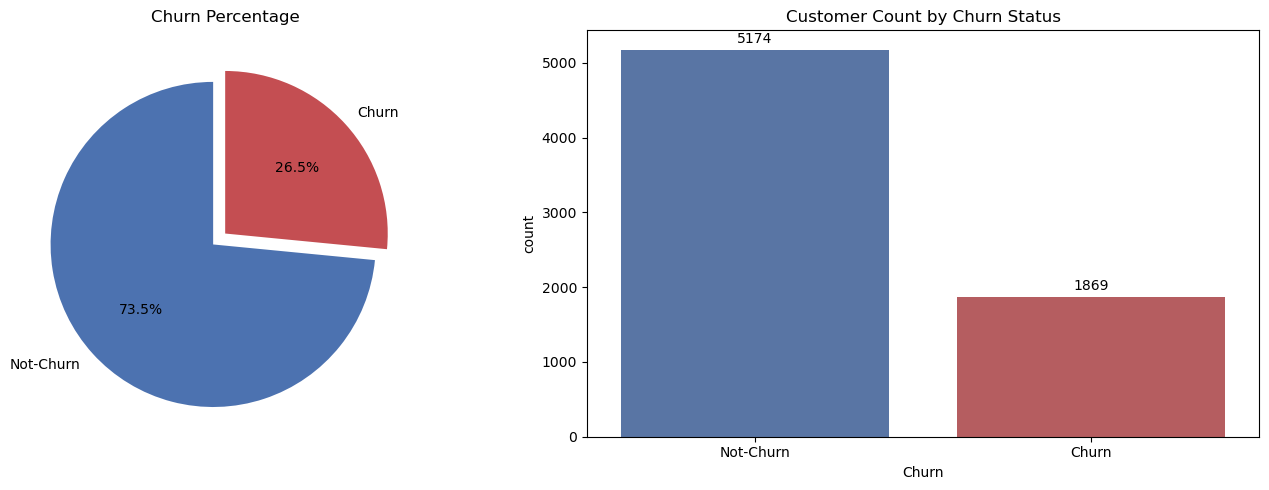

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Churn"].value_counts().plot.pie(
    autopct="%1.1f%%",
    ax=axes[0],
    colors=["#4c72b0", "#c44e52"],
    labels=["Not-Churn", "Churn"],
    startangle=90,
    explode=(0.1, 0),
)
axes[0].set_ylabel("")
axes[0].set_title("Churn Percentage")

ax = sns.countplot(
    x="Churn",
    data=df,
    palette=["#4c72b0", "#c44e52"],
    ax=axes[1],
    hue="Churn",
    legend=False,
)
axes[1].set_xticklabels(["Not-Churn", "Churn"])
axes[1].set_title("Customer Count by Churn Status")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

### Horizontal bar chart grouped by Contract and Churn

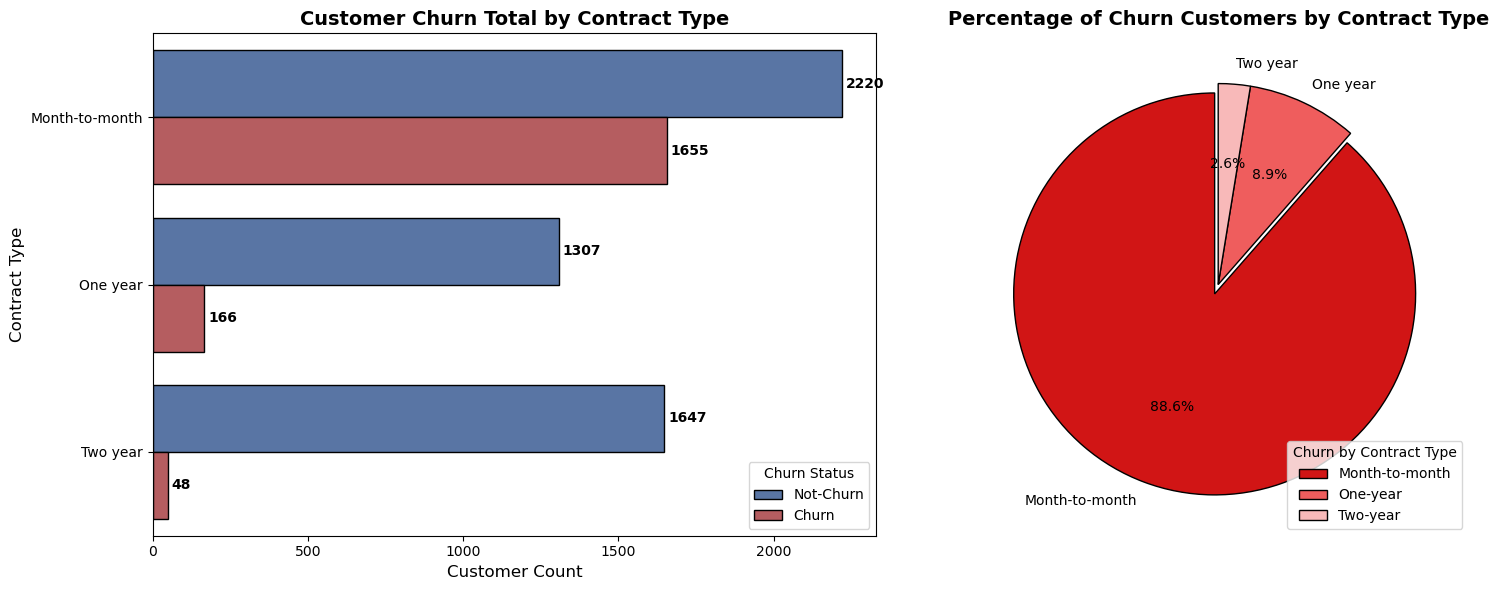

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = sns.countplot(
    y="Contract",
    data=df,
    palette=["#4c72b0", "#c44e52"],
    hue="Churn",
    edgecolor="black",
    ax=axes[0],
)

axes[0].set_title(
    "Customer Churn Total by Contract Type", fontsize=14, weight="bold"
)
axes[0].set_xlabel("Customer Count", fontsize=12)
axes[0].set_ylabel("Contract Type", fontsize=12)

for container in ax1.containers:
    ax1.bar_label(container, padding=3, weight="bold")

axes[0].legend(
    title="Churn Status", labels=["Not-Churn", "Churn"], loc="lower right"
)

churn_df = df[df["Churn"] == "Yes"]
contract_churn_counts = churn_df["Contract"].value_counts()
colors_pie = ["#d11515", "#ef5d5d", "#f8b9b9"]

axes[1].pie(
    contract_churn_counts,
    labels=contract_churn_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_pie,
    explode=(0.05, 0, 0),
    wedgeprops={"edgecolor": "black", "linewidth": 1, "antialiased": True},
)

axes[1].set_title(
    "Percentage of Churn Customers by Contract Type", fontsize=14, weight="bold"
)

axes[1].legend(
    title="Churn by Contract Type", labels=["Month-to-month", "One-year", "Two-year"], loc="lower right"
)

plt.tight_layout()
plt.show()

 - As we can see, around 89% of Churn Customers have a month-to-month contract, therefore, an action plan that could be implemented would be to offer discounts for signing a one-year or two-year contract, adding benefits to the contracted services that make sense for the customer to choose a longer term contract over a month-to-month plan. For example, by signing a two-year contract, the customer gets the **StreamingMovies** service for one year at no additional charge.

### Gender, Senior Citizen, Partner and Dependents (customers info)

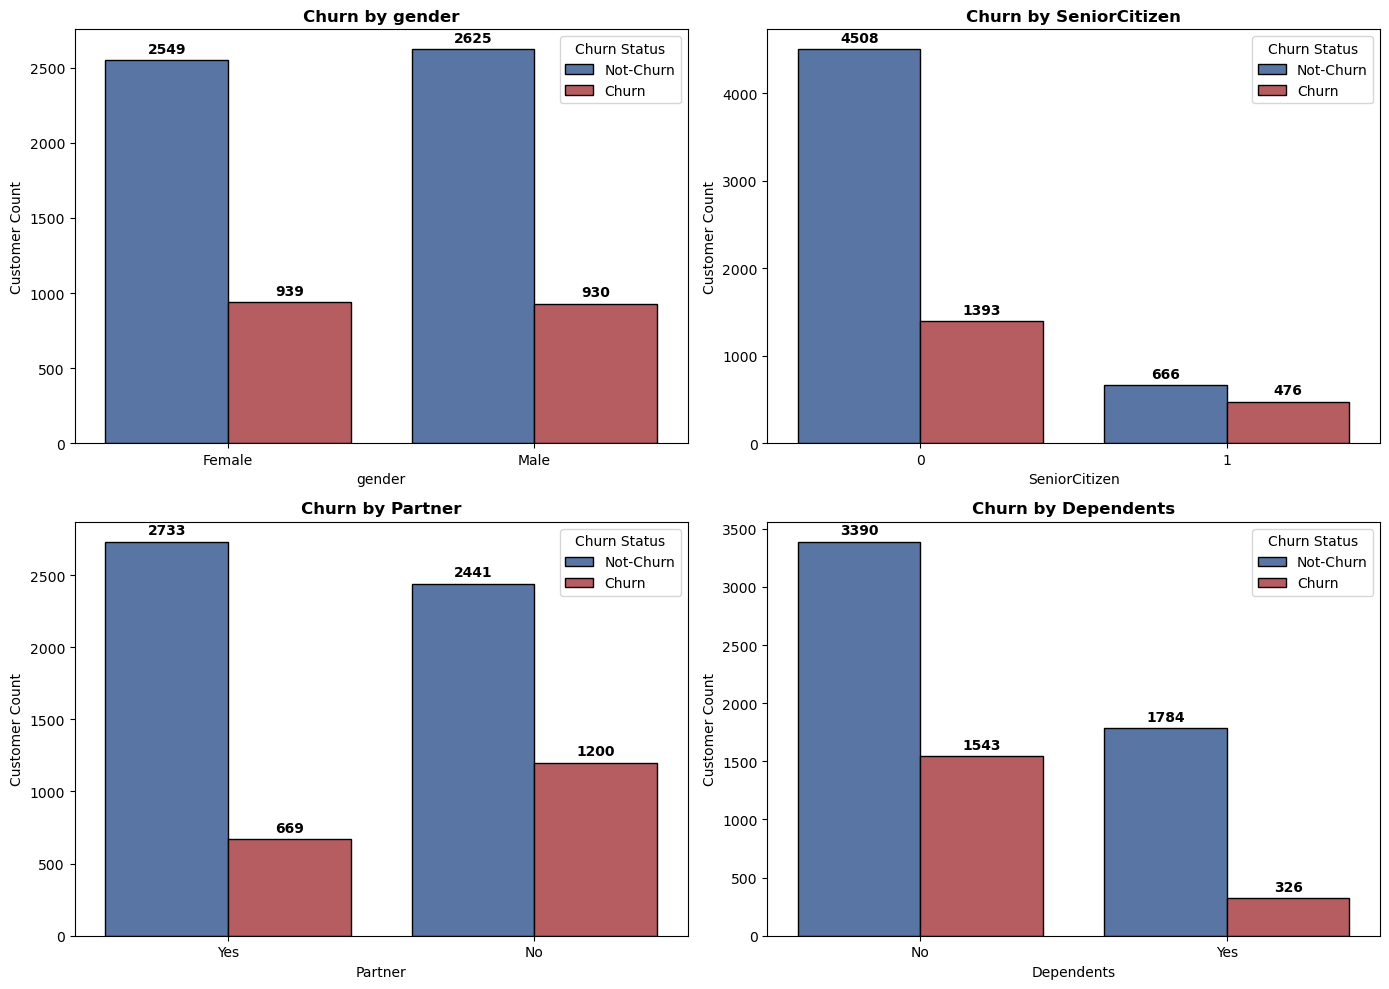

In [11]:
demographic_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(demographic_features):
    ax = sns.countplot(
        x=feature, 
        hue='Churn', 
        data=df, 
        palette=['#4c72b0', '#c44e52'], 
        edgecolor='black',
        ax=axes[i]
    )
    
    axes[i].set_title(f'Churn by {feature}', fontsize=12, weight='bold')
    axes[i].set_xlabel(feature, fontsize=10)
    axes[i].set_ylabel('Customer Count', fontsize=10)
    
    for container in ax.containers:
        ax.bar_label(container, padding=3, weight='bold')
    
    axes[i].legend(title='Churn Status', labels=['Not-Churn', 'Churn'], loc='upper right')

plt.tight_layout()
plt.show()

 - **Churn by Gender**: the churn rate is similar for both male and female customers.
 - **Churn by Senior Citizens**: the number of senior citizen customers is very low. On the other hand, approximately 42% of them canceled the service (a high churn rate).
 - **Churn by Partner**: customers with a partner have a lower churn rate (≃ 20%) compared to those with no partner (≃ 33%).
 - **Churn by Dependents**: customers with no dependents have a higher churn rate (≃ 31%) compared to those with dependents (≃ 15%)

### Phone Service, Multiple Lines, Internet Service, Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies (services subscribed info)

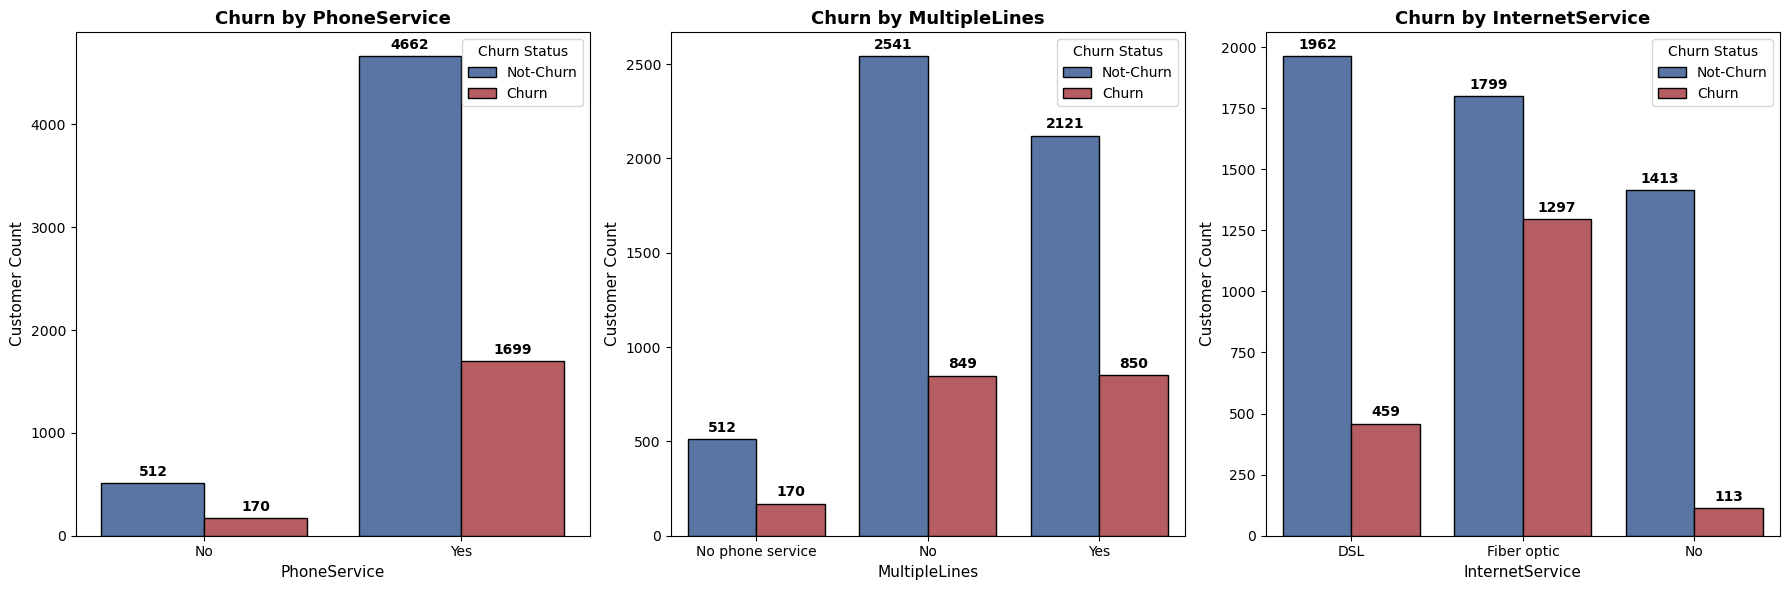

In [12]:
service_features = ["PhoneService", "MultipleLines", "InternetService"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, feature in enumerate(service_features):
    ax = sns.countplot(
        x=feature,
        hue="Churn",
        data=df,
        palette=["#4c72b0", "#c44e52"],
        edgecolor="black",
        ax=axes[i],
    )

    axes[i].set_title(f"Churn by {feature}", fontsize=13, weight="bold")
    axes[i].set_xlabel(feature, fontsize=11)
    axes[i].set_ylabel("Customer Count", fontsize=11)

    for container in ax.containers:
        ax.bar_label(container, padding=3, weight="bold")

    axes[i].legend(
        title="Churn Status", labels=["Not-Churn", "Churn"], loc="upper right"
    )

plt.tight_layout()
plt.show()

 - **Churn by Phone Service**: the churn rate of customers with no phone service (≃ 25%) is slightly lower than those with phone service (≃ 27%).
 - **Churn by Multiple Lines**: in this case, customers with multiple lines have the highest churn rate within this category (≃ 29%).
 - **Churn by Internet Service**: here, the fiber optic category shows the highest churn rate (≃ 42%).

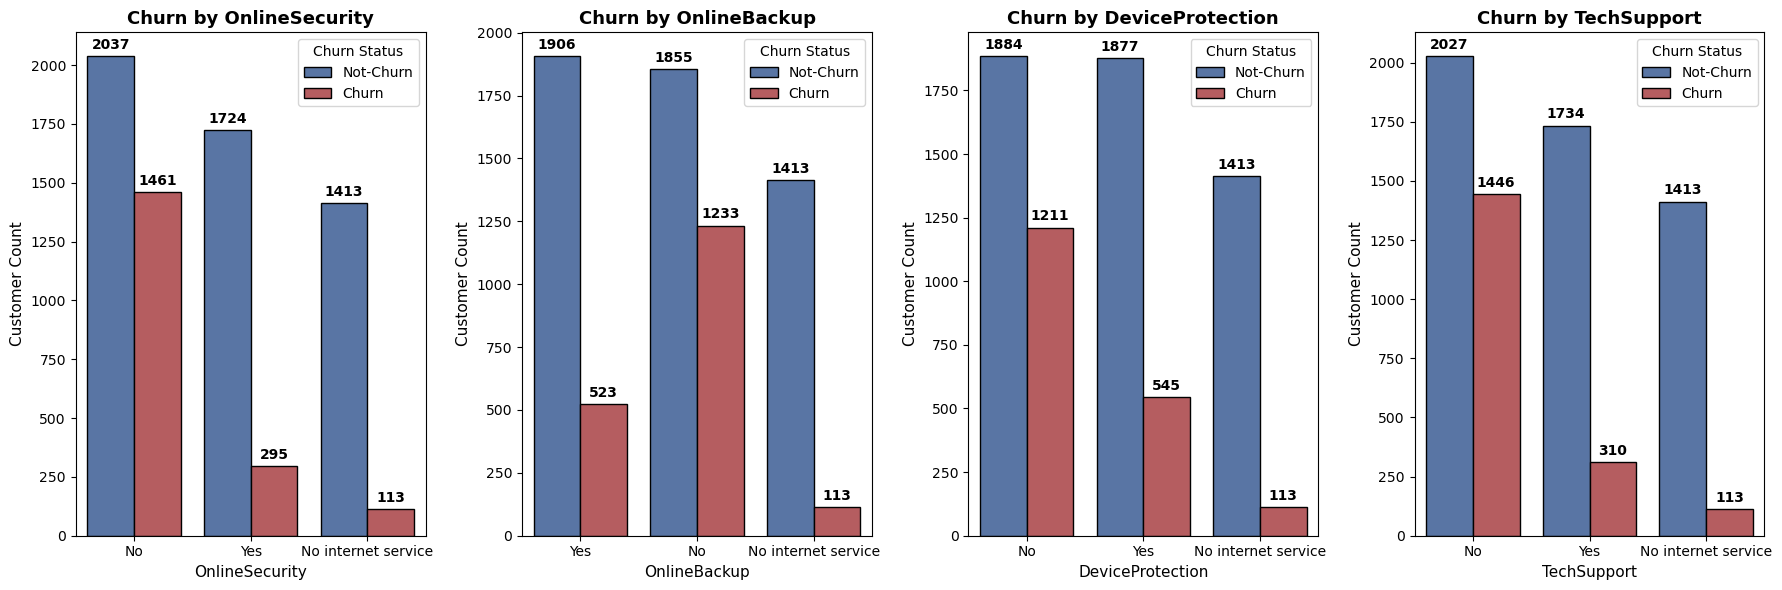

In [13]:
service_features = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for i, feature in enumerate(service_features):
    ax = sns.countplot(
        x=feature,
        hue="Churn",
        data=df,
        palette=["#4c72b0", "#c44e52"],
        edgecolor="black",
        ax=axes[i],
    )

    axes[i].set_title(f"Churn by {feature}", fontsize=13, weight="bold")
    axes[i].set_xlabel(feature, fontsize=11)
    axes[i].set_ylabel("Customer Count", fontsize=11)

    for container in ax.containers:
        ax.bar_label(container, padding=3, weight="bold")

    axes[i].legend(
        title="Churn Status", labels=["Not-Churn", "Churn"], loc="upper right"
    )

plt.tight_layout()
plt.show()

 - **Churn by Online Security**: the category with no online security has the highest churn rate (≃ 42%).
 - **Churn by Online Backup**: the category with no online backup has the highest churn rate (≃ 40%).
 - **Churn by Device Protection**: the category with no device protection has the highest churn rate (≃ 39%).
 - **Churn by Tech Support**: the category with no tech support has the highest churn rate (≃ 42%).

Note: A high number of customers switched their service provider due to poor security services, as the charts above show.

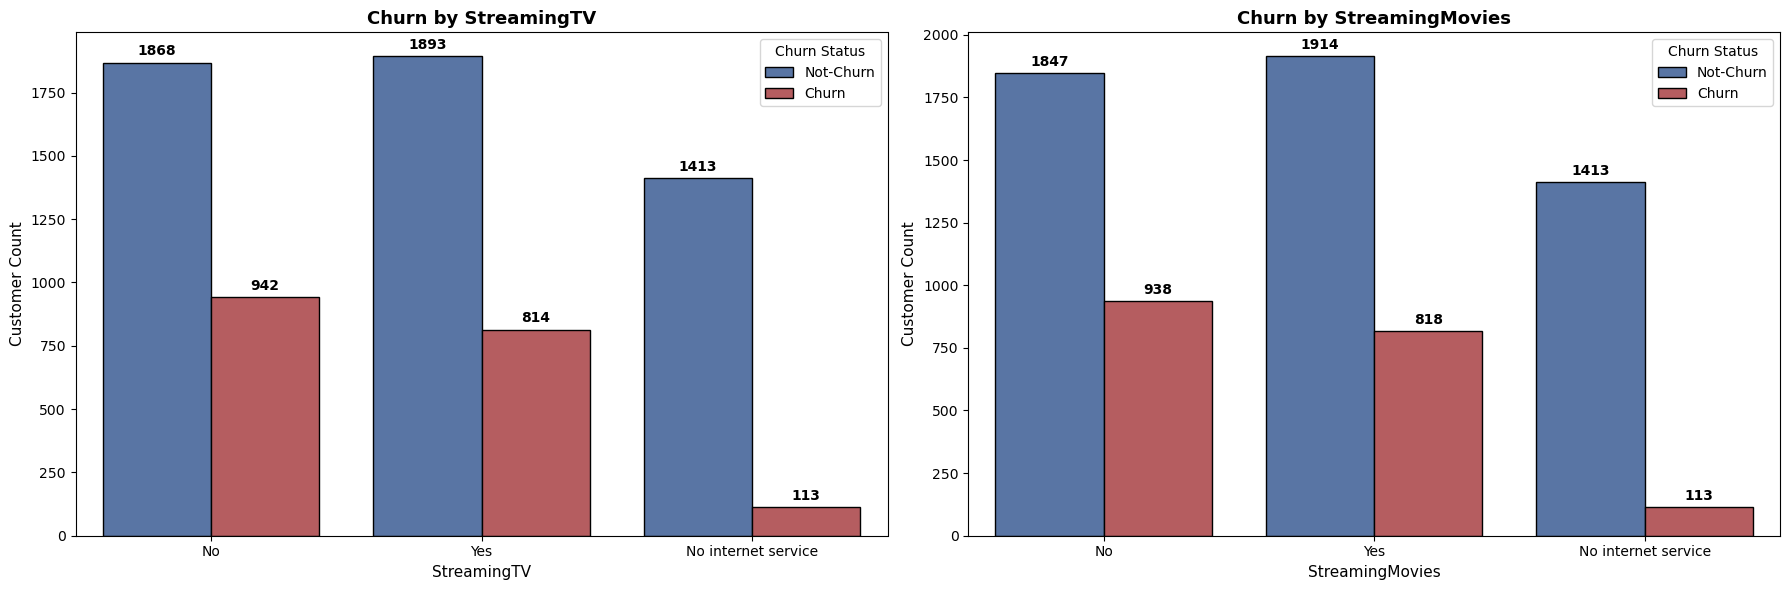

In [14]:
service_features = ["StreamingTV", "StreamingMovies"]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for i, feature in enumerate(service_features):
    ax = sns.countplot(
        x=feature,
        hue="Churn",
        data=df,
        palette=["#4c72b0", "#c44e52"],
        edgecolor="black",
        ax=axes[i],
    )

    axes[i].set_title(f"Churn by {feature}", fontsize=13, weight="bold")
    axes[i].set_xlabel(feature, fontsize=11)
    axes[i].set_ylabel("Customer Count", fontsize=11)

    for container in ax.containers:
        ax.bar_label(container, padding=3, weight="bold")

    axes[i].legend(
        title="Churn Status", labels=["Not-Churn", "Churn"], loc="upper right"
    )

plt.tight_layout()
plt.show()

 - **Churn by Streaming TV**: the churn rate of customers with no Streaming TV service (≃ 34%) is slightly higher than those with the service (≃ 30%).
 - **Churn by Streaming Movies**: the churn rate of customers with no Streaming Movies service (≃ 34%) is slightly higher than those with the service (≃ 30%).

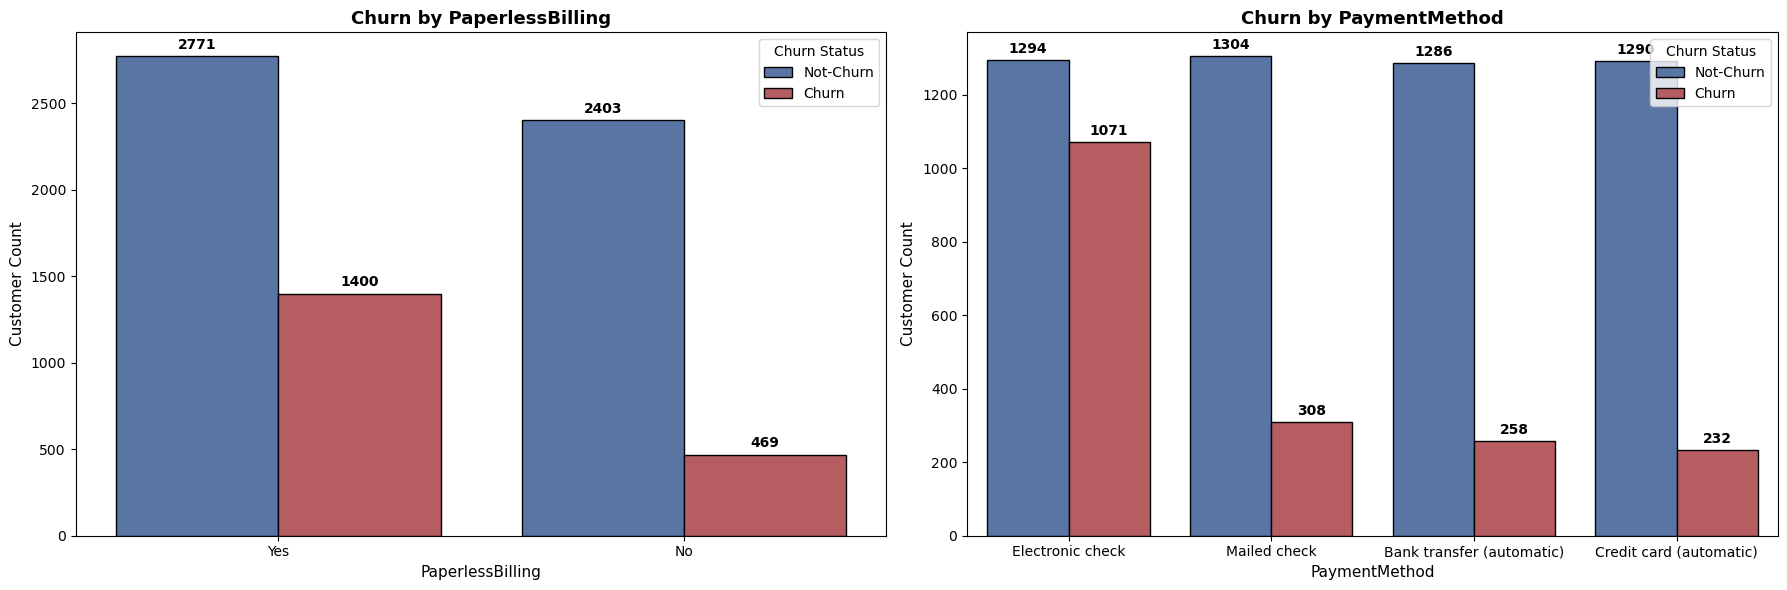

In [15]:
service_features = ["PaperlessBilling", "PaymentMethod"]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for i, feature in enumerate(service_features):
    ax = sns.countplot(
        x=feature,
        hue="Churn",
        data=df,
        palette=["#4c72b0", "#c44e52"],
        edgecolor="black",
        ax=axes[i],
    )

    axes[i].set_title(f"Churn by {feature}", fontsize=13, weight="bold")
    axes[i].set_xlabel(feature, fontsize=11)
    axes[i].set_ylabel("Customer Count", fontsize=11)

    for container in ax.containers:
        ax.bar_label(container, padding=3, weight="bold")

    axes[i].legend(
        title="Churn Status", labels=["Not-Churn", "Churn"], loc="upper right"
    )

plt.tight_layout()
plt.show()

## 2. Data Preprocessing and Feature Engineering

### Copying dataframe

In [16]:
df_processed = df.copy()

### Transforming **TotalCharges** column to numeric and 

In [17]:
df_processed["TotalCharges"] = pd.to_numeric(
    df_processed["TotalCharges"], errors="coerce"
)

### Imputing missing values in **TotalCharges** using the median

In [18]:
df_processed["TotalCharges"].fillna(
    df_processed["TotalCharges"].median(), inplace=True
)

### Dropping **customerID** column

In [19]:
df_processed.drop("customerID", axis=1, inplace=True)

### Converting **Churn** column to binary values

In [20]:
df_processed["Churn"] = df_processed["Churn"].map({"Yes": 1, "No": 0})

## 3. Data Splitting

### Separating features (X) and target variable (y)

In [21]:
X = df_processed.drop("Churn", axis=1)
y = df_processed["Churn"]

### Applying One-Hot Encoding to categorical features

In [22]:
X = pd.get_dummies(X, drop_first=True)

In [23]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7043 non-null   int64  
 1   tenure                                 7043 non-null   int64  
 2   MonthlyCharges                         7043 non-null   float64
 3   TotalCharges                           7043 non-null   float64
 4   gender_Male                            7043 non-null   bool   
 5   Partner_Yes                            7043 non-null   bool   
 6   Dependents_Yes                         7043 non-null   bool   
 7   PhoneService_Yes                       7043 non-null   bool   
 8   MultipleLines_No phone service         7043 non-null   bool   
 9   MultipleLines_Yes                      7043 non-null   bool   
 10  InternetService_Fiber optic            7043 non-null   bool   
 11  Inte

### Splitting the dataset into Training and Testing sets

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 4. Model Training

In [25]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()

scale_weight = neg_count / pos_count

xgb_model = XGBClassifier(
    scale_pos_weight=scale_weight,
    max_depth=3,
    learning_rate=0.03,
    n_estimators=300,
    random_state=42,
    min_child_weight=3,
    gamma=1,
    reg_lambda=5,
    reg_alpha=0.7,
    subsample=0.7,
    eval_metric="logloss",
)

xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


## 5. Model Evaluation

### Model Inference

In [26]:
y_pred = xgb_model.predict(X_test)
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

### Confusion Matrix

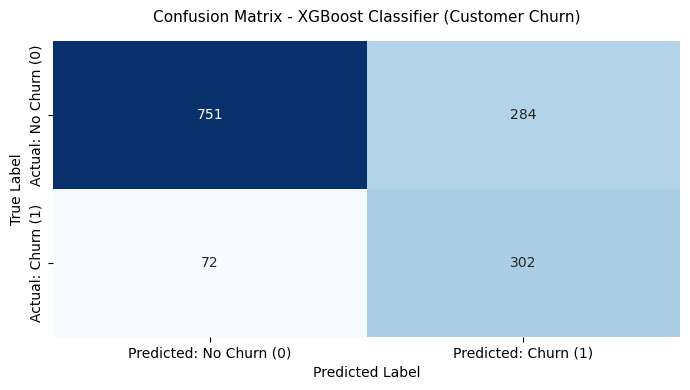

In [27]:
cm_xgb = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 4))
sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted: No Churn (0)", "Predicted: Churn (1)"],
    yticklabels=["Actual: No Churn (0)", "Actual: Churn (1)"],
)

plt.title(
    "Confusion Matrix - XGBoost Classifier (Customer Churn)",
    fontsize=11,
    pad=14,
)
plt.xlabel("Predicted Label", fontsize=10)
plt.ylabel("True Label", fontsize=10)
plt.tight_layout()
plt.show()

### Classification report

In [28]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



### ROC-AUC Score

In [29]:
print(round(roc_auc_score(y_test, y_pred_proba), 4))

0.8478


## 6. Exporting Machine Learning Model

In [30]:
joblib.dump(
    {
        "model": xgb_model,
        "columns": list(X.columns),
        "threshold": 0.5,
    },
    "xgb_model.joblib",
)

['xgb_model.joblib']